# Set Up

In [1]:
# Import packages
import pandas as pd
import numpy as np
import re #remove punctuation
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from collections import Counter

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.linear_model import LogisticRegression


In [2]:
# Load in data
df = pd.read_csv("model_ready_bills.csv")
df.head()

,bill_id,congress,type,origin_chamber,introduced_date,title,sponsor_bioguide,sponsor_party,sponsor_state,policy_area,...,seniority,freshman,chair,subchair,power_cmte,maj_leader,min_leader,state_leg,outcome,commemorative
0,116-hjres-1,116,hjres,House,2019-01-03,Making further continuing appropriations for t...,L000480,D,NY,Economics and Public Finance,...,16.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,2,0
1,116-hjres-10,116,hjres,House,2019-01-03,Proposing an amendment to the Constitution of ...,F000466,R,PA,Congress,...,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,0
2,116-hjres-100,116,hjres,House,2020-11-19,Providing for congressional disapproval of the...,O000173,D,MN,International Affairs,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1,0
3,116-hjres-101,116,hjres,House,2020-11-19,Providing for congressional disapproval of the...,O000173,D,MN,International Affairs,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1,0
4,116-hjres-102,116,hjres,House,2020-11-19,Providing for congressional disapproval of the...,O000173,D,MN,International Affairs,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1,0


In [3]:
# Remove Other sponsor party
df = df[df['sponsor_party'] != "Other"]
df['sponsor_party'].value_counts()


sponsor_party
D    25790
R    19500
Name: count, dtype: int64

# Clean bill titles

In [4]:
# Set bill titles to lowercase
df['lower_title'] = df['title'].str.lower()

# Keep only letters in the text (remove punctuation and numbers)
df['lower_title'] = df['lower_title'].apply(lambda x: re.sub(r'[^a-zA-Z\s]', '', x))

# Split the bill title into a list of words
df['title_list'] = df['lower_title'].str.split()

df.head()

,bill_id,congress,type,origin_chamber,introduced_date,title,sponsor_bioguide,sponsor_party,sponsor_state,policy_area,...,chair,subchair,power_cmte,maj_leader,min_leader,state_leg,outcome,commemorative,lower_title,title_list
0,116-hjres-1,116,hjres,House,2019-01-03,Making further continuing appropriations for t...,L000480,D,NY,Economics and Public Finance,...,1.0,1.0,1.0,0.0,0.0,0.0,2,0,making further continuing appropriations for t...,"[making, further, continuing, appropriations, ..."
1,116-hjres-10,116,hjres,House,2019-01-03,Proposing an amendment to the Constitution of ...,F000466,R,PA,Congress,...,0.0,0.0,0.0,0.0,0.0,0.0,1,0,proposing an amendment to the constitution of ...,"[proposing, an, amendment, to, the, constituti..."
2,116-hjres-100,116,hjres,House,2020-11-19,Providing for congressional disapproval of the...,O000173,D,MN,International Affairs,...,0.0,0.0,0.0,0.0,0.0,1.0,1,0,providing for congressional disapproval of the...,"[providing, for, congressional, disapproval, o..."
3,116-hjres-101,116,hjres,House,2020-11-19,Providing for congressional disapproval of the...,O000173,D,MN,International Affairs,...,0.0,0.0,0.0,0.0,0.0,1.0,1,0,providing for congressional disapproval of the...,"[providing, for, congressional, disapproval, o..."
4,116-hjres-102,116,hjres,House,2020-11-19,Providing for congressional disapproval of the...,O000173,D,MN,International Affairs,...,0.0,0.0,0.0,0.0,0.0,1.0,1,0,providing for congressional disapproval of the...,"[providing, for, congressional, disapproval, o..."


In [5]:
# Stack each word in the list onto a separate row 
word_list = df['title_list'].explode()

# Count the number of times each word appears
word_count = Counter(word_list)

In [6]:
# Word count dataframe
word_count = pd.DataFrame.from_dict(word_count, orient = 'index', columns=['count'])
word_count = word_count.reset_index()
word_count.columns = ['word', 'count']
word_count.head()

,word,count
0,making,100
1,further,33
2,continuing,58
3,appropriations,304
4,for,10082


In [7]:
# Create one list of all the words to create a wordcloud
# combined_text = " ".join(map(str, word_list))

# Stopwords

In [8]:
# https://codefinity.com/courses/v2/c68c1f2e-2c90-4d5d-8db9-1e97ca89d15e/026d736a-1860-4e3e-a915-b926ca2d9ed8/b9469e7f-9eb7-40ce-8941-2fb946782907

from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from nltk import pos_tag
from nltk.corpus import wordnet as wn
import nltk
nltk.download('wordnet')
nltk.download('stopwords')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('punkt_tab')
# Initialize the lemmatizer
lem = WordNetLemmatizer()


# Function to map NLTK's POS tags to the format used by the WordNet lemmatizer
def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return wn.ADJ
    elif treebank_tag.startswith('V'):
        return wn.VERB
    elif treebank_tag.startswith('R'):
        return wn.ADV
    else:
        # Default to noun if no match is found or starts with 'N'
        return wn.NOUN  

[nltk_data] Downloading package wordnet to /Users/tiede/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to /Users/tiede/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /Users/tiede/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package punkt_tab to /Users/tiede/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [9]:
# Create list of stop/filler words to exclude from data

default_stopwords = set(stopwords.words('english'))
custom_stopwords = [
    'i', 'ii', 'iii', 'iv', 'v', 'vi', 'vii', 'viii', 'ix', 'x',
    'xi', 'xii', 'xiii', 'xiv', 'xv', 'xvi', 'xvii', 'xviii', 'xix', 'xx',
    'xxi', 'xxii', 'xxiii', 'xxiv', 'xxv', 'xxvi', 'xxvii', 'xxviii', 'xxix', 'xxx',
    'xxxi', 'xxxii', 'xxxiii', 'xxxiv', 'xxxv', 'xxxvi', 'xxxvii', 'xxxviii', 'xxxix', 'xl',
    'xli', 'xlii', 'xliii', 'xliv', 'xlv', 'xlvi', 'xlvii', 'xlviii', 'xlix', 'l'
]

extended_stopwords = default_stopwords.union(custom_stopwords)

In [10]:
# Create dataframe with Sponsor Party, one row per non filler word in bill title

df_words = df[['sponsor_party', 'title_list']]
df_words = df_words.explode(column = 'title_list') #Each title word is on a separate row

tagged_tokens = pos_tag(df_words['title_list']) # Tag each word with the part of speech POS (noun, verb, etc)

# Lemmatize each token with its POS tag
lemmatized_tokens = [lem.lemmatize(token, get_wordnet_pos(tag)) for token, tag in tagged_tokens] 
df_words['lem_title'] = lemmatized_tokens

# Filter rows that contain a stopword 
df_clean = df_words[~df_words['lem_title'].isin(extended_stopwords)]
df_clean.head()

,sponsor_party,title_list,lem_title
0,D,making,make
0,D,continuing,continue
0,D,appropriations,appropriation
0,D,department,department
0,D,homeland,homeland


In [11]:
# Lemmatize and filter within sentences
# https://codefinity.com/courses/v2/c68c1f2e-2c90-4d5d-8db9-1e97ca89d15e/026d736a-1860-4e3e-a915-b926ca2d9ed8/b9469e7f-9eb7-40ce-8941-2fb946782907

# Create dataframe with Sponsor Party, one row per original bill title, and cleaned version of title

def lemming(text):
    '''
    Lemmatize a string of words
    '''
    tokens = word_tokenize(text)
    tagged_tokens = pos_tag(tokens)

    lem_tokens = [lem.lemmatize(token, get_wordnet_pos(tag)) for token, tag in tagged_tokens]
    clean_lem = [word for word in lem_tokens if word not in extended_stopwords]

    separator = ' '
    cleaned = separator.join(clean_lem)
    return cleaned

In [12]:
df['clean_title'] = df['lower_title'].apply(lemming)
df.head()

,bill_id,congress,type,origin_chamber,introduced_date,title,sponsor_bioguide,sponsor_party,sponsor_state,policy_area,...,subchair,power_cmte,maj_leader,min_leader,state_leg,outcome,commemorative,lower_title,title_list,clean_title
0,116-hjres-1,116,hjres,House,2019-01-03,Making further continuing appropriations for t...,L000480,D,NY,Economics and Public Finance,...,1.0,1.0,0.0,0.0,0.0,2,0,making further continuing appropriations for t...,"[making, further, continuing, appropriations, ...",make continue appropriation department homelan...
1,116-hjres-10,116,hjres,House,2019-01-03,Proposing an amendment to the Constitution of ...,F000466,R,PA,Congress,...,0.0,0.0,0.0,0.0,0.0,1,0,proposing an amendment to the constitution of ...,"[proposing, an, amendment, to, the, constituti...",propose amendment constitution united state pr...
2,116-hjres-100,116,hjres,House,2020-11-19,Providing for congressional disapproval of the...,O000173,D,MN,International Affairs,...,0.0,0.0,0.0,0.0,1.0,1,0,providing for congressional disapproval of the...,"[providing, for, congressional, disapproval, o...",provide congressional disapproval propose fore...
3,116-hjres-101,116,hjres,House,2020-11-19,Providing for congressional disapproval of the...,O000173,D,MN,International Affairs,...,0.0,0.0,0.0,0.0,1.0,1,0,providing for congressional disapproval of the...,"[providing, for, congressional, disapproval, o...",provide congressional disapproval propose fore...
4,116-hjres-102,116,hjres,House,2020-11-19,Providing for congressional disapproval of the...,O000173,D,MN,International Affairs,...,0.0,0.0,0.0,0.0,1.0,1,0,providing for congressional disapproval of the...,"[providing, for, congressional, disapproval, o...",provide congressional disapproval propose fore...


In [13]:
test_list = df['clean_title'].str.split().explode()

In [14]:
test_list = Counter(test_list)

In [15]:

# Word count dataframe
test_count = pd.DataFrame.from_dict(test_list, orient = 'index', columns=['count'])
test_count = test_count.reset_index()
test_count.columns = ['word', 'count']
test_count.sort_values(by = 'count').head(20) #Check typos

,word,count
11305,factoring,1
11304,abortionrelated,1
11303,romania,1
11302,carjackers,1
11301,terminology,1
11300,freebird,1
3313,mcculloch,1
3311,concentration,1
3307,cox,1
3293,phmsa,1


# Model 1 - Multinomial Naive Bayes - TF-IDF

In [16]:
# Set up X and Y variables
X = df['clean_title']
y = df['sponsor_party']

In [17]:
# Set up text for TF-IDF analysis
td = TfidfVectorizer(max_features = 4500)
X = td.fit_transform(X).toarray()

In [18]:
#Create training and test sets 
# 0.7/0.3 proportion
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 1)

In [19]:
# Set up Multinomial Naive Bayes analysis
classifier = MultinomialNB()
classifier.fit(X_train, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[18047.,13656.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.56,-0.84]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U1](2,)","['D','R']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 4500)","[[ 2.16, 2.4 , 2.6 ,..., 1.84,13.25, 0. ], [ 0. , 2.15, 0. ,..., 0.58, 8.93, 4.32]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 4500)","[[ -9.45, -9.37, -9.31,..., -9.55, -7.94,-10.6 ], [-10.4 , -9.25,-10.4 ,..., -9.94, -8.1 , -8.73]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4500


In [20]:
# Predict y with Naive Bayers
y_pred = classifier.predict(X_test)

In [21]:
# Classification metrics - Naive Bayes
class_report_NB = classification_report(y_test, y_pred)
print(class_report_NB)

              precision    recall  f1-score   support

           D       0.69      0.83      0.75      7743
           R       0.69      0.50      0.58      5844

    accuracy                           0.69     13587
   macro avg       0.69      0.66      0.67     13587
weighted avg       0.69      0.69      0.68     13587



# Model 2 - Multinomial Naive Bayes - Count

In [22]:
# Set up X and Y variables
X = df['clean_title']
y = df['sponsor_party']

In [23]:
# Set up text for TF-IDF analysis
td = CountVectorizer(max_features = 4500)
X = td.fit_transform(X).toarray()

In [24]:
#Create training and test sets 
# 0.7/0.3 proportion
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 1)

In [25]:
# Set up Multinomial Naive Bayes analysis
classifier = MultinomialNB()
classifier.fit(X_train, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[18047.,13656.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.56,-0.84]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U1](2,)","['D','R']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 4500)","[[ 5., 5., 5.,..., 3.,29., 0.], [ 0., 5., 0.,..., 1.,16., 5.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 4500)","[[ -9.69, -9.69, -9.69,...,-10.1 , -8.09,-11.49], [-11.35, -9.56,-11.35,...,-10.66, -8.52, -9.56]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4500


In [26]:
# Predict y with Naive Bayes
y_pred = classifier.predict(X_test)

In [27]:
# Classification metrics - Naive Bayes
class_report_NB_count = classification_report(y_test, y_pred)
print(class_report_NB_count)

              precision    recall  f1-score   support

           D       0.68      0.83      0.74      7743
           R       0.67      0.47      0.56      5844

    accuracy                           0.67     13587
   macro avg       0.67      0.65      0.65     13587
weighted avg       0.67      0.67      0.66     13587



# Model 3 - Logistic Regression - Count

In [28]:
X = df['clean_title']
y = df['sponsor_party']

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 1)

In [30]:
vectorizer = CountVectorizer(ngram_range = (1,2))
vectors = vectorizer.fit_transform(X_train)

In [31]:

test_vectors = vectorizer.transform(X_test)

In [32]:
log_reg = LogisticRegression(
    random_state=5030, solver="saga", max_iter=1_000
)
log_reg.fit(vectors, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",5030
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'saga'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_r

In [33]:
y_pred = log_reg.predict(test_vectors)

In [34]:
# Classification metrics - Logistic Regression with Count Vectorizer
class_report_count = classification_report(y_test, y_pred)
print(class_report_count)

              precision    recall  f1-score   support

           D       0.76      0.84      0.80      7743
           R       0.76      0.65      0.70      5844

    accuracy                           0.76     13587
   macro avg       0.76      0.75      0.75     13587
weighted avg       0.76      0.76      0.76     13587



# Model 4 - Logistic Regression - TF-IDF

In [35]:
X = df['clean_title']
y = df['sponsor_party']

In [36]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 1)

In [37]:
vectorizer = TfidfVectorizer(ngram_range = (1,2))

train_vectors = vectorizer.fit_transform(X_train)
test_vectors = vectorizer.transform(X_test)

In [38]:
log_reg = LogisticRegression(
    random_state=5030, solver="saga", max_iter=1_000
)
log_reg.fit(train_vectors, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",5030
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'saga'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_r

In [39]:
y_pred = log_reg.predict(test_vectors)


In [40]:
# Classification metrics - Logistic Regression TF-IDF
class_report_tf = classification_report(y_test, y_pred)
print(class_report_tf)

              precision    recall  f1-score   support

           D       0.73      0.85      0.79      7743
           R       0.75      0.59      0.66      5844

    accuracy                           0.74     13587
   macro avg       0.74      0.72      0.72     13587
weighted avg       0.74      0.74      0.73     13587



# All Classification Reports

In [41]:
print(f'Logistic TF_IDF: {class_report_tf}')


Logistic TF_IDF:               precision    recall  f1-score   support

           D       0.73      0.85      0.79      7743
           R       0.75      0.59      0.66      5844

    accuracy                           0.74     13587
   macro avg       0.74      0.72      0.72     13587
weighted avg       0.74      0.74      0.73     13587



In [42]:
print(f'Logistic Count: {class_report_count}')

Logistic Count:               precision    recall  f1-score   support

           D       0.76      0.84      0.80      7743
           R       0.76      0.65      0.70      5844

    accuracy                           0.76     13587
   macro avg       0.76      0.75      0.75     13587
weighted avg       0.76      0.76      0.76     13587



In [43]:
print(f'Naive Bayes TF-IDF: {class_report_NB}')

Naive Bayes TF-IDF:               precision    recall  f1-score   support

           D       0.69      0.83      0.75      7743
           R       0.69      0.50      0.58      5844

    accuracy                           0.69     13587
   macro avg       0.69      0.66      0.67     13587
weighted avg       0.69      0.69      0.68     13587



In [44]:
print(f'Naive Bayes Count: {class_report_NB_count}')

Naive Bayes Count:               precision    recall  f1-score   support

           D       0.68      0.83      0.74      7743
           R       0.67      0.47      0.56      5844

    accuracy                           0.67     13587
   macro avg       0.67      0.65      0.65     13587
weighted avg       0.67      0.67      0.66     13587



# AUC Curve - Logistic Count

In [45]:
df['sponsor_binary'] = df['sponsor_party'].replace({'D': 0, 'R': 1}).astype('int')

In [46]:
X = df['clean_title']
y = df['sponsor_binary'] #use binary variable to plot the AUC curve

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 1)

vectorizer = CountVectorizer(ngram_range = (1,2)) #Also tested with (1,1) engrams and (2,2) bigrams which had lower metrics
vectors = vectorizer.fit_transform(X_train)

test_vectors = vectorizer.transform(X_test)

log_reg = LogisticRegression(
    random_state=5030, solver="liblinear"
)
log_reg.fit(vectors, y_train)

y_pred = log_reg.predict(test_vectors)

class_report_tf = classification_report(y_test, y_pred)
print(class_report_tf)

              precision    recall  f1-score   support

           0       0.76      0.84      0.80      7743
           1       0.76      0.65      0.70      5844

    accuracy                           0.76     13587
   macro avg       0.76      0.75      0.75     13587
weighted avg       0.76      0.76      0.76     13587



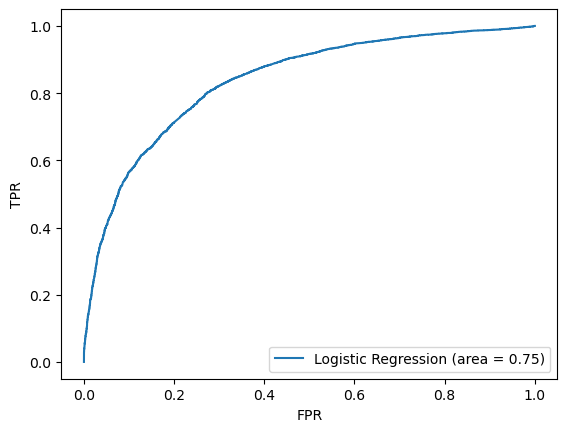

In [47]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve

logit_roc_auc = roc_auc_score(y_test, y_pred)
fpr, tpr, thresholds = roc_curve(y_test, log_reg.predict_proba(test_vectors)[:,1])
plt.figure()
plt.plot(fpr, tpr, label='Logistic Regression (area = %0.2f)' % logit_roc_auc)
plt.legend(loc="lower right")
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.show()

In [48]:
from sklearn.metrics import confusion_matrix

confusion_matrix = confusion_matrix(y_test, y_pred)
print(confusion_matrix)

[[6511 1232]
 [2017 3827]]


# Logistic Regression - TFIDF AUC


In [49]:
X = df['clean_title']
y = df['sponsor_binary'] #use binary variable to plot the AUC curve

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 1)

vectorizer = TfidfVectorizer(ngram_range = (1,2)) #Also tested with (1,1) engrams and (2,2) bigrams which had lower metrics
vectors = vectorizer.fit_transform(X_train)

test_vectors = vectorizer.transform(X_test)

log_reg = LogisticRegression(
    random_state=5030, solver="liblinear"
)
log_reg.fit(vectors, y_train)

y_pred = log_reg.predict(test_vectors)

class_report_tf = classification_report(y_test, y_pred)
print(class_report_tf)

              precision    recall  f1-score   support

           0       0.73      0.85      0.79      7743
           1       0.75      0.59      0.66      5844

    accuracy                           0.74     13587
   macro avg       0.74      0.72      0.72     13587
weighted avg       0.74      0.74      0.73     13587



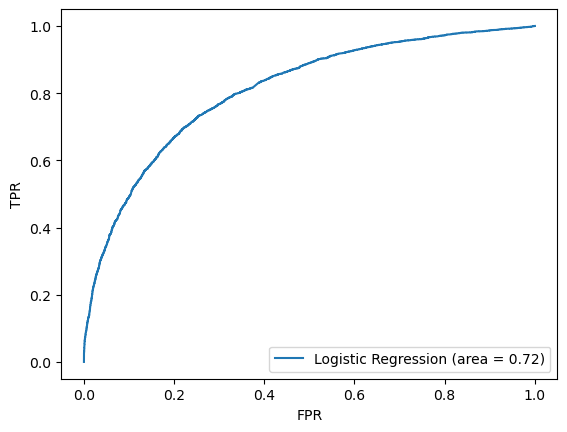

In [50]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve

logit_roc_auc = roc_auc_score(y_test, y_pred)
fpr, tpr, thresholds = roc_curve(y_test, log_reg.predict_proba(test_vectors)[:,1])
plt.figure()
plt.plot(fpr, tpr, label='Logistic Regression (area = %0.2f)' % logit_roc_auc)
plt.legend(loc="lower right")
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.show()

# To Do: Combine Count Vectorizer Bill Title Variable with other variables in Logistic Regression model, CV, semantic clustering